# Movie budget and revenue: Seaborn and linear regression

Day 78 of Udemy's *100 Days of Code: The Complete Python Pro Bootcamp*.

**The question:** do films with a higher production budget earn more money?

**What you learn:** cleaning money columns with pandas, filtering and
grouping films, Seaborn scatter and bubble charts, `regplot`, and a linear
regression with scikit-learn (intercept, slope and R-squared).

The code lives in the `movie_regression` package; the notebook calls it step
by step.

## Step 1: Project goals and the data

Load the raw file. The money columns are still text such as `$110,000`, so pandas cannot calculate with them yet.

In [1]:
%matplotlib inline
from IPython.display import display

from movie_regression.application import analysis, cleaning
from movie_regression.application.regression import fit_budget_to_revenue
from movie_regression.application.report import PREDICTION_BUDGET
from movie_regression.infrastructure.data import DATA_FILE, load_films
from movie_regression.presentation import charts

raw = load_films(DATA_FILE)
display(raw.head())
raw.shape

,Rank,Release_Date,Movie_Title,USD_Production_Budget,USD_Worldwide_Gross,USD_Domestic_Gross
0,5293,8/2/1915,The Birth of a Nation,"$110,000","$11,000,000","$10,000,000"
1,5140,5/9/1916,Intolerance,"$385,907",$0,$0
2,5230,12/24/1916,"20,000 Leagues Under the Sea","$200,000","$8,000,000","$8,000,000"
3,5299,9/17/1920,Over the Hill to the Poorhouse,"$100,000","$3,000,000","$3,000,000"
4,5222,1/1/1925,The Big Parade,"$245,000","$22,000,000","$11,000,000"


(5391, 6)

## Step 2: Explore and clean the data

Check rows, NaN values and duplicates, then turn the money columns into numbers and `Release_Date` into a date.

In [2]:
structure = cleaning.describe_structure(raw)
print(structure)

films = cleaning.prepare(raw)
display(films.dtypes.to_frame("dtype"))
films.describe()

Structure(rows=5391, columns=6, has_nan=False, duplicate_rows=0, dtypes={'Rank': 'int64', 'Release_Date': 'str', 'Movie_Title': 'str', 'USD_Production_Budget': 'str', 'USD_Worldwide_Gross': 'str', 'USD_Domestic_Gross': 'str'})


,dtype
Rank,int64
Release_Date,datetime64[us]
Movie_Title,str
USD_Production_Budget,int64
USD_Worldwide_Gross,int64
USD_Domestic_Gross,int64


,Rank,Release_Date,USD_Production_Budget,USD_Worldwide_Gross,USD_Domestic_Gross
count,5391.000000,5391,5.391000e+03,5.391000e+03,5.391000e+03
mean,2696.000000,2003-09-19 15:02:02.203672,3.111374e+07,8.885542e+07,4.123552e+07
min,1.000000,1915-08-02 00:00:00,1.100000e+03,0.000000e+00,0.000000e+00
25%,1348.500000,1999-12-02 12:00:00,5.000000e+06,3.865206e+06,1.330902e+06
50%,2696.000000,2006-06-23 00:00:00,1.700000e+07,2.745045e+07,1.719220e+07
75%,4043.500000,2011-11-23 00:00:00,4.000000e+07,9.645446e+07,5.234369e+07
max,5391.000000,2020-12-31 00:00:00,4.250000e+08,2.783919e+09,9.366622e+08
std,1556.391981,NaN,4.052380e+07,1.684578e+08,6.602935e+07


## Step 3: Films with zero revenue

The cheapest and dearest films, the films that earned nothing at all, and the films released after the data was collected (1 May 2018) that must be removed.

In [3]:
display(analysis.lowest_budget_films(films))
display(analysis.highest_budget_films(films))
print("Zero domestic gross:", len(analysis.zero_domestic_films(films)))
zero_worldwide = analysis.zero_worldwide_films(films)
print("Zero worldwide gross:", len(zero_worldwide))
display(zero_worldwide.head(10))

print("Unreleased films:", len(cleaning.unreleased_films(films)))
clean = cleaning.remove_unreleased(films)
print(f"Films losing money: {analysis.share_losing_money(clean):.1f}%")

,Rank,Release_Date,Movie_Title,USD_Production_Budget,USD_Worldwide_Gross,USD_Domestic_Gross
2427,5391,2005-05-08,My Date With Drew,1100,181041,181041


,Rank,Release_Date,Movie_Title,USD_Production_Budget,USD_Worldwide_Gross,USD_Domestic_Gross
3529,1,2009-12-18,Avatar,425000000,2783918982,760507625


Zero domestic gross: 512
Zero worldwide gross: 357


,Rank,Release_Date,Movie_Title,USD_Production_Budget,USD_Worldwide_Gross,USD_Domestic_Gross
5388,96,2020-12-31,Singularity,175000000,0,0
5387,126,2018-12-18,Aquaman,160000000,0,0
5384,321,2018-09-03,A Wrinkle in Time,103000000,0,0
5385,366,2018-10-08,Amusement Park,100000000,0,0
5058,880,2015-11-12,The Ridiculous 6,60000000,0,0
5338,879,2017-04-08,The Dark Tower,60000000,0,0
5389,1119,2020-12-31,Hannibal the Conqueror,50000000,0,0
5092,1435,2015-12-31,The Crow,40000000,0,0
3300,1631,2008-12-31,Black Water Transit,35000000,0,0
5045,1656,2015-10-30,Freaks of Nature,33000000,0,0


Unreleased films: 7
Films losing money: 37.3%


## Step 4: International releases

Zero domestic gross but some worldwide gross: filtered with `.loc[]` and `&`, and again with `.query()`.

In [4]:
international = analysis.international_releases(films)
print(len(international), len(analysis.international_releases_query(films)))
international.head(10)

155 155


,Rank,Release_Date,Movie_Title,USD_Production_Budget,USD_Worldwide_Gross,USD_Domestic_Gross
71,4310,1956-02-16,Carousel,3380000,3220,0
1579,5087,2001-02-11,Everything Put Together,500000,7890,0
1744,3695,2001-12-31,The Hole,7500000,10834406,0
2155,4236,2003-12-31,Nothing,4000000,63180,0
2203,2513,2004-03-31,The Touch,20000000,5918742,0
2309,4623,2004-10-12,Freeze Frame,2000000,105377,0
2409,4747,2005-04-11,Wal-Mart: The High Cost of Low Price,1500000,58692,0
2578,2944,2005-12-31,Dungeons & Dragons: Wrath of the Dragon God,15000000,909822,0
2579,4531,2005-12-31,Chicken Tikka Masala,2160000,37865,0
2751,1629,2006-09-22,Bandidas,35000000,19282590,0


## Step 5: Seaborn scatter and bubble charts

Budget against worldwide gross: first a plain scatter plot, then a bubble chart where colour and size show the revenue.

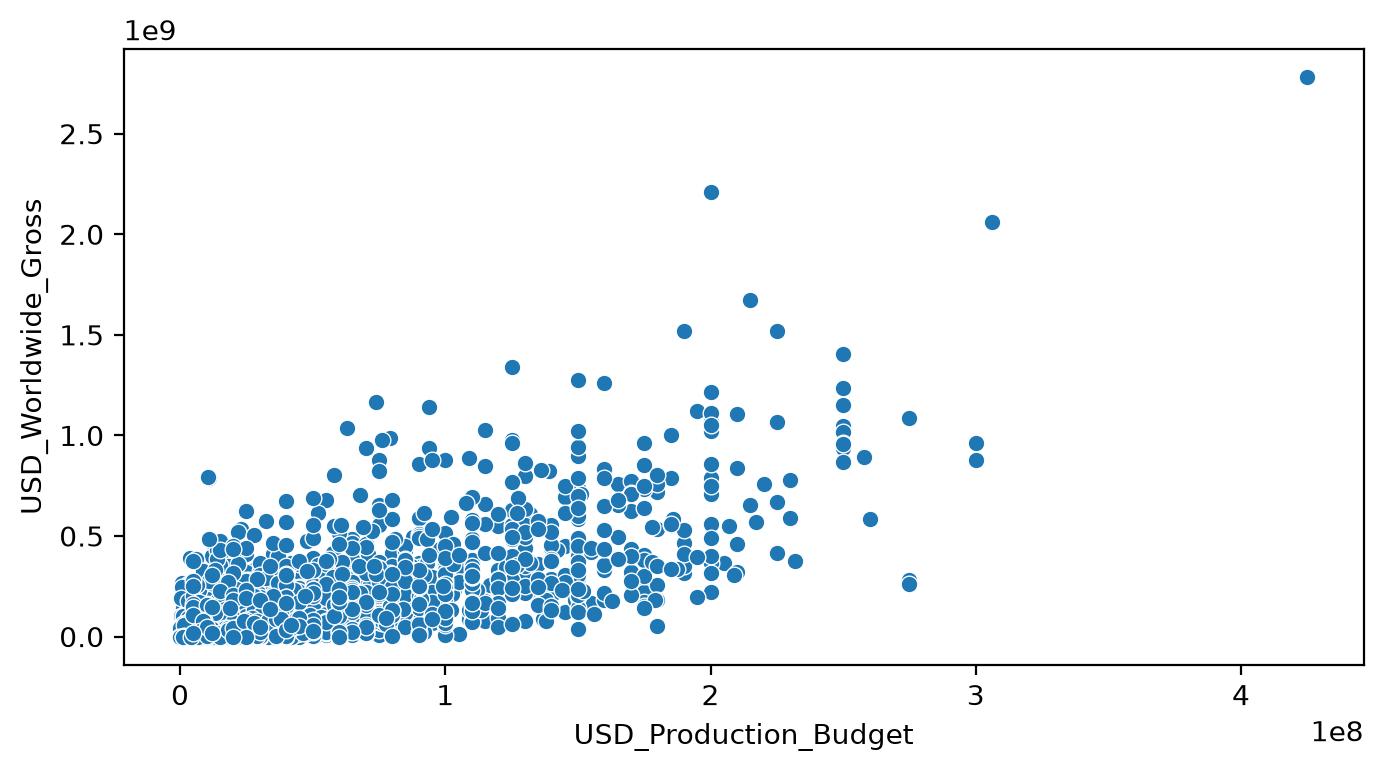

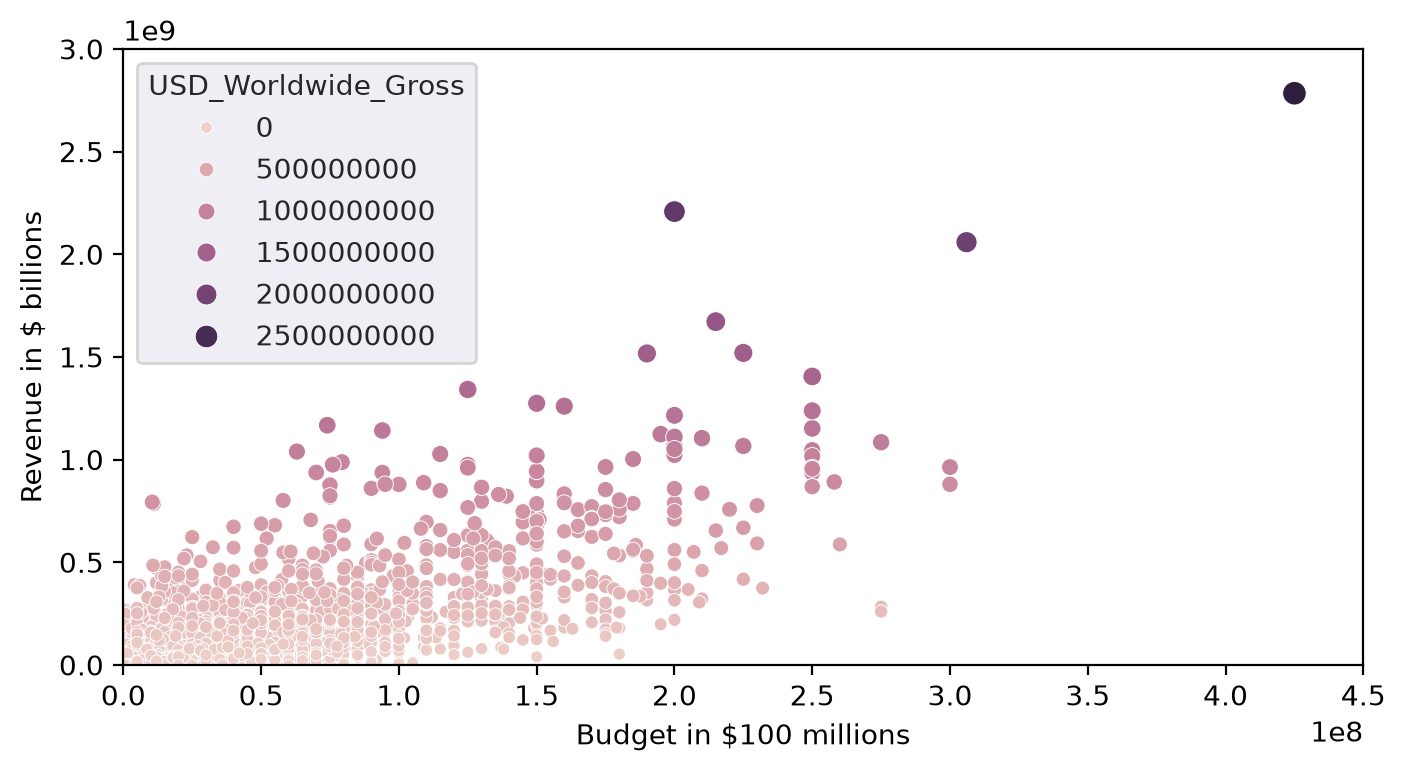

In [5]:
display(charts.scatter_chart(clean))
charts.bubble_chart(clean)

## Step 6: Films per decade

Floor division turns a year into a decade: 1992 and 1999 both become 1990.

,Release_Date,Decade
0,1915-08-02,1910
1,1916-05-09,1910
2,1916-12-24,1910
3,1920-09-17,1920
4,1925-01-01,1920


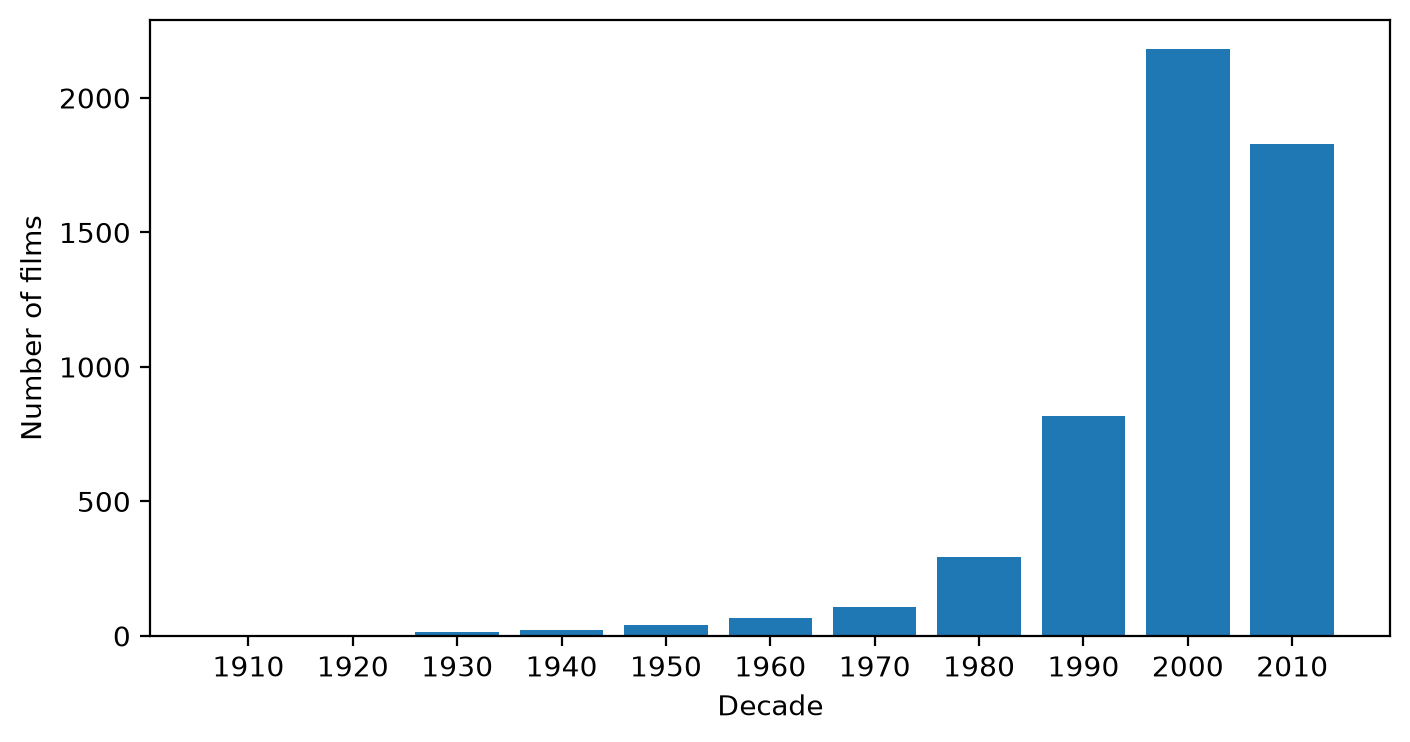

In [6]:
with_decade = analysis.add_decade(clean)
display(with_decade[["Release_Date", "Decade"]].head())
charts.decade_chart(clean)

## Step 7: Regression plots with Seaborn

Seaborn's `regplot` draws the points and a fitted line. Old films (before 1970) use the default style; new films get their own dot and line colours.

Old films: 153 New films: 5231


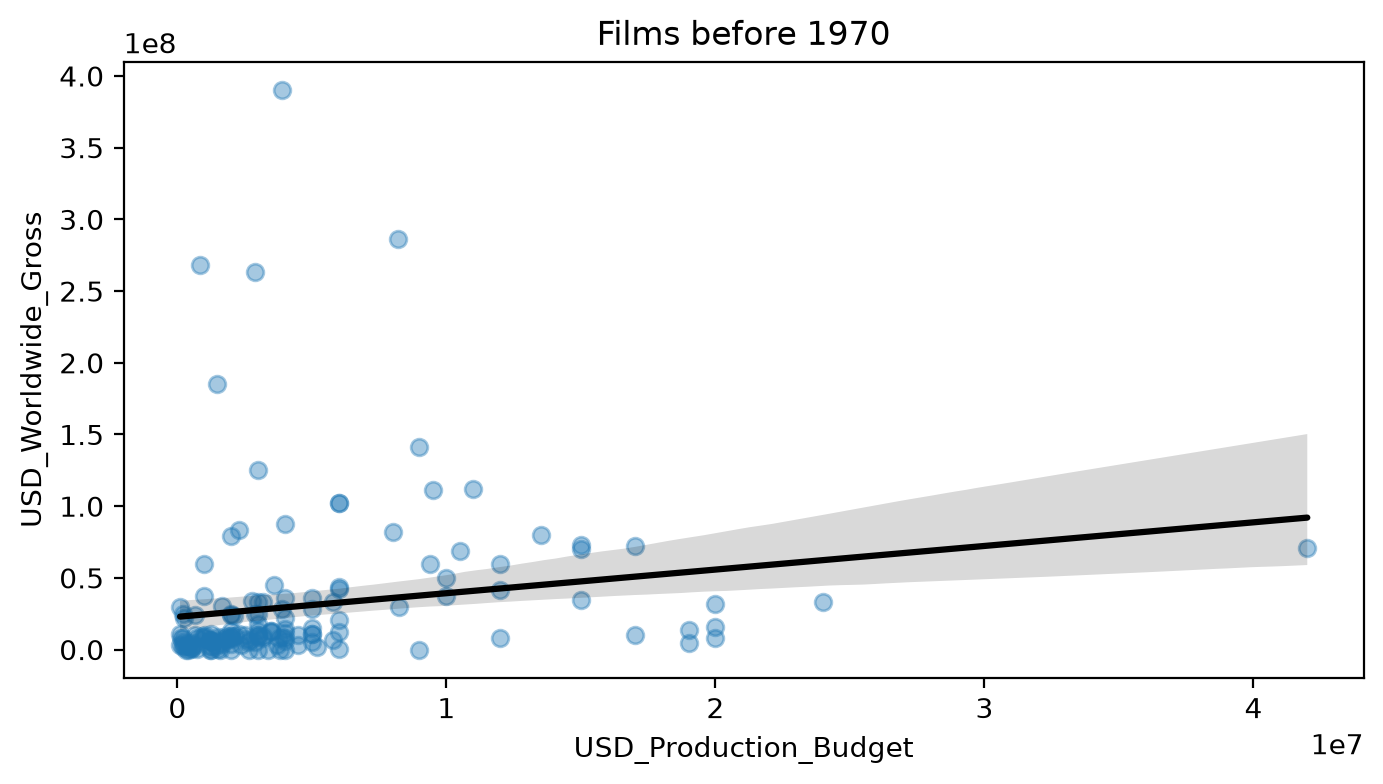

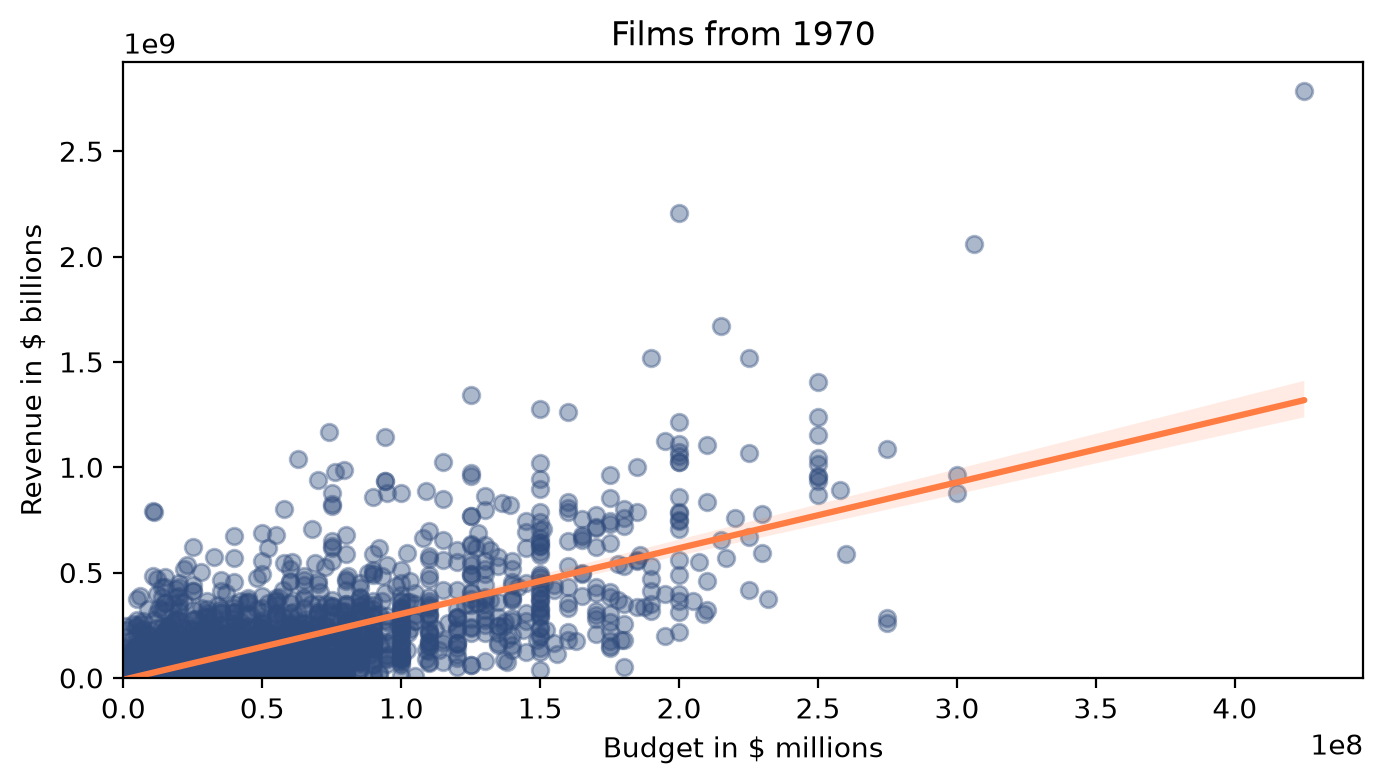

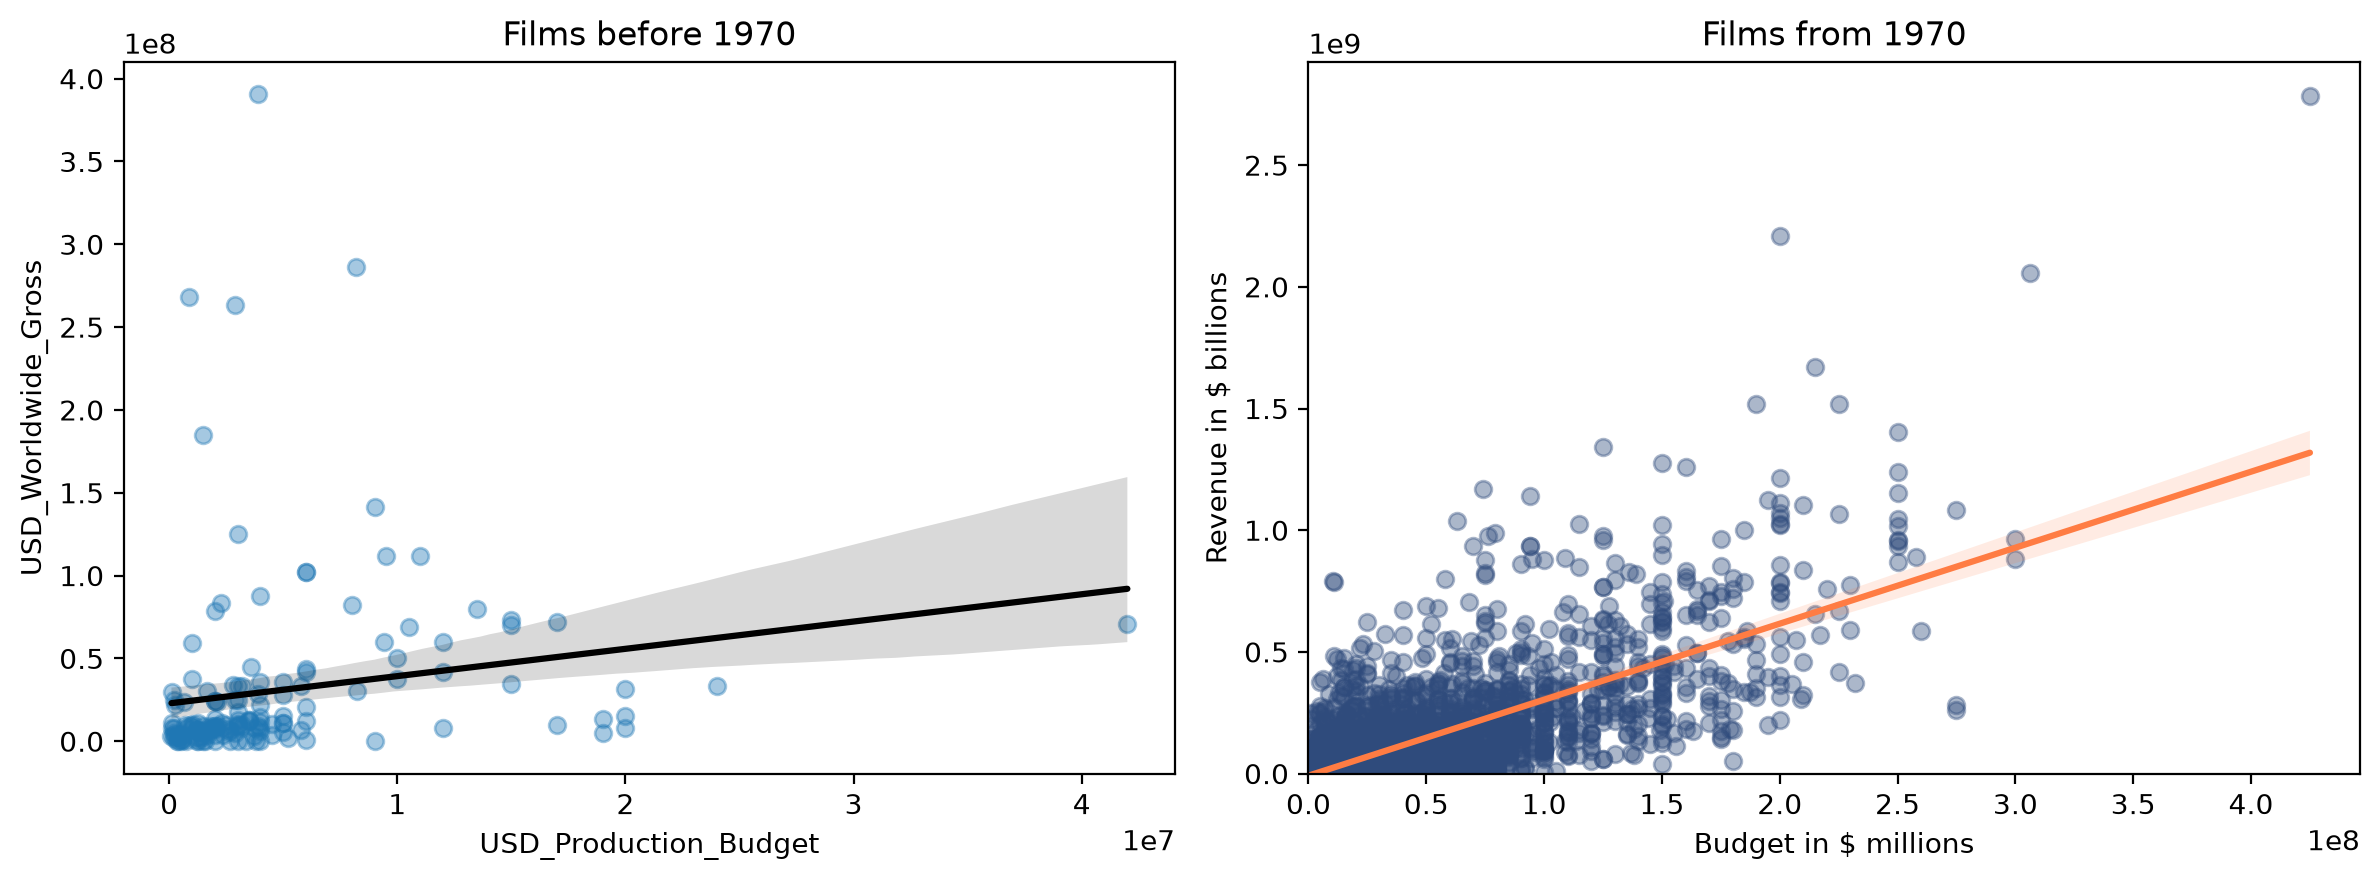

In [7]:
old, new = analysis.split_old_and_new(clean)
print("Old films:", len(old), "New films:", len(new))
display(charts.regression_chart(old, title="Films before 1970"))
display(
    charts.regression_chart(
        new,
        dot_colour=charts.NEW_FILMS_DOT_COLOUR,
        line_colour=charts.NEW_FILMS_LINE_COLOUR,
        title="Films from 1970",
    )
)
charts.regression_comparison_chart(old, new)

## Step 8: Linear regression with scikit-learn

Fit `revenue = intercept + slope * budget` and draw the line from the estimates. R-squared tells how much of the variation in revenue the budget explains.

RegressionResult(intercept=-8650768.006610423, slope=3.1225959173210978, r_squared=0.5577032617720403)


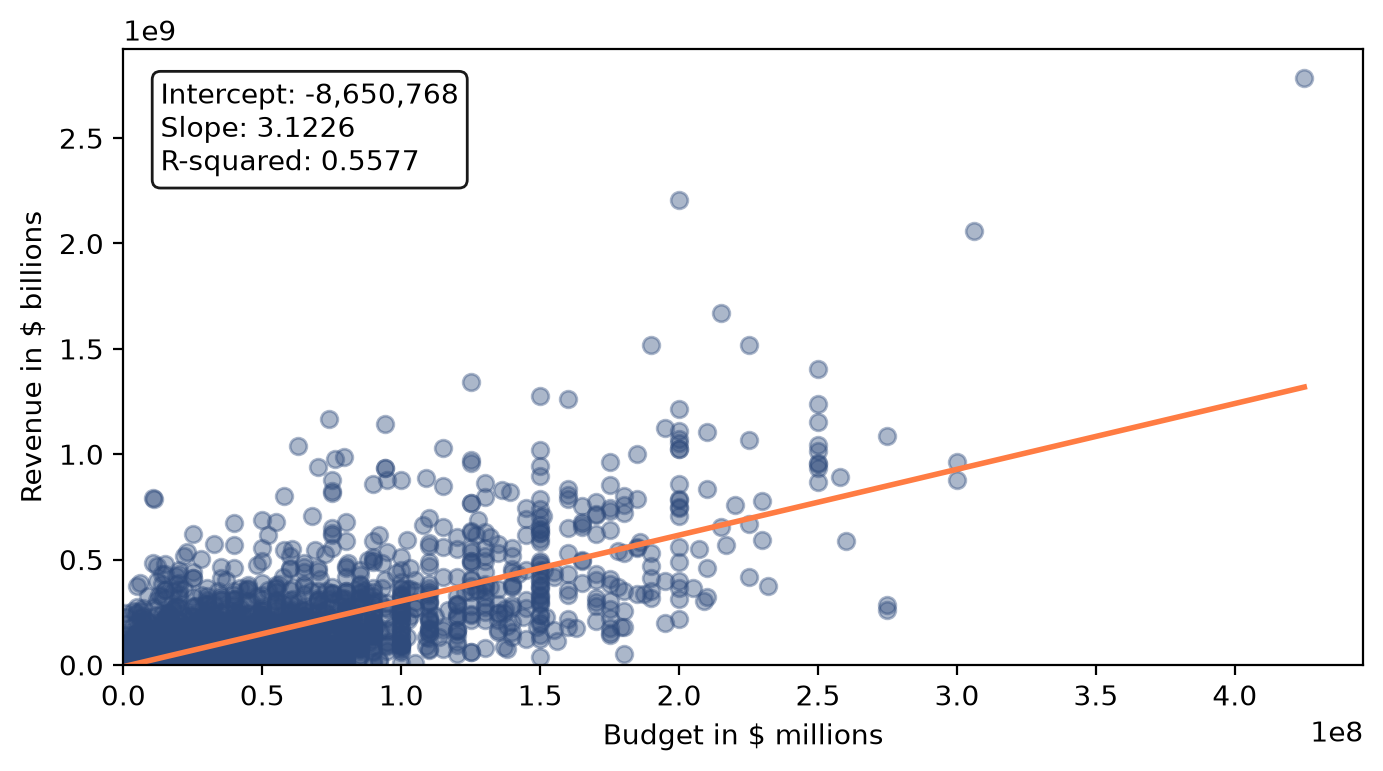

In [8]:
new_result = fit_budget_to_revenue(new)
print(new_result)
charts.fitted_line_chart(new, new_result)

## Step 9: Summary and prediction

Compare old and new films and predict the revenue of a film with a $150 million budget.

In [9]:
old_result = fit_budget_to_revenue(old)
for label, result in (("Old", old_result), ("New", new_result)):
    print(
        f"{label}: intercept {result.intercept:,.0f}, slope {result.slope:.4f}, "
        f"R-squared {result.r_squared:.4f}, "
        f"prediction for ${PREDICTION_BUDGET:,}: "
        f"${result.predict(PREDICTION_BUDGET):,.0f}"
    )

Old: intercept 22,821,539, slope 1.6477, R-squared 0.0294, prediction for $150,000,000: $269,978,510
New: intercept -8,650,768, slope 3.1226, R-squared 0.5577, prediction for $150,000,000: $459,738,620
